In [32]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.workflows import analyze_session, batch_analyze_sessions, combine_animal_sessions
from src.viz.SessionVisualizer import SessionVisualizer
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM041'
record_date = '251128'
experiment_name = 'tiling_3_120um'

combined_df = combine_animal_sessions('SAM041', 'tiling_120um', base_data_dir=data_dir)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[SessionCombiner] Found 9 sessions across D:/data-distance-coding-project/multi-session-data\SAM041_tiling_120um\SAM041_tiling_120um_sessions.txt

[1/9] Processing session: 251126_SAM041_tiling_1_120um
  Loading registered DataFrame from 251126_SAM041_tiling_1_120um_dataframe_registered.pkl
  Widefield coordinates already present
  Added 1299 cells from this session

[2/9] Processing session: 251126_SAM041_tiling_2_120um
  Loading registered DataFrame from 251126_SAM041_tiling_2_120um_dataframe_registered.pkl
  Widefield coordinates already present
  Added 2130 cells from this session

[3/9] Processing session: 251128_SAM041_tiling_3_120um
  Loading registered DataFrame from 251128_SAM041_tiling_3_120um_dataframe_registered.pkl
  Widefield coordinates already present
  Added 2025 cells from this session

[4/9] Processing session: 251128_SAM041_tiling_4_120um
  Loading standard DataFrame from 251128_

In [ ]:
def get_cells(combined_df, condition, session, area):



    cells = combined_df[(combined_df['condition'] == condition) & (combined_df['session_name'] == session) & (combined_df['area'] == area)]
    return cells


0           0
1           1
2           2
3           3
4           4
         ... 
12943    1634
12944    1653
12945    1655
12946    1770
12947    1786
Name: cell_id, Length: 12948, dtype: int64

In [ ]:
def filter_by_reliability(input_df, reliable_type='reliable',threshold=0.85):

    if reliable_type == 'reliable':
        output_df = input_df[
            (input_df['monocular'].apply(lambda x: x['reliable']) == True) &
            (input_df['binocular'].apply(lambda x: x['reliable']) == True) &
            ((input_df['monocular'].apply(lambda x: x['reliable_corr']) >= threshold) |
            (input_df['binocular'].apply(lambda x: x['reliable_corr']) >= threshold))
        ]

    elif reliable_type == 'not_reliable':
        output_df = input_df[
            (input_df['monocular'].apply(lambda x: x['reliable']) == False) &
            (input_df['binocular'].apply(lambda x: x['reliable']) == False) &
            ((input_df['monocular'].apply(lambda x: x['reliable_corr']) < threshold) and
            (input_df['binocular'].apply(lambda x: x['reliable_corr']) < threshold))
        ]

    return output_df

output_df = filter_by_reliability(combined_df, reliable_type='reliable',threshold=0.85)

TypeError: filter_by_reliability() missing 1 required positional argument: 'input_df'

In [ ]:



reliable = combined_df[
    (combined_df['monocular'].apply(lambda x: x['reliable']) == True) &
    (combined_df['binocular'].apply(lambda x: x['reliable']) == True) &
    ((combined_df['monocular'].apply(lambda x: x['reliable_corr']) >= 0.85) |
    (combined_df['binocular'].apply(lambda x: x['reliable_corr']) >= 0.85))
]
a
print(reliable)AI_ADDRCONFIG

       cell_id       ODI         RF  distance  \
6            6  0.542293 -24.000000         3   
33          34 -0.267792  58.500000         0   
38          39  0.100210 -22.500000         1   
49          50  0.030157 -24.000000         1   
84          85  0.430436  60.000000         1   
...        ...       ...        ...       ...   
12397      411  0.243794  29.491525         3   
12435      449 -0.352665  31.016949         2   
12445      461  0.689106  29.491525         3   
12491      509  0.105865  23.389831         3   
12627      670  0.513400  31.016949         1   

                                               monocular  \
6      {'RF': -10.5, 'reliable': True, 'reliable_corr...   
33     {'RF': 60.0, 'reliable': True, 'reliable_corr'...   
38     {'RF': -22.5, 'reliable': True, 'reliable_corr...   
49     {'RF': -24.0, 'reliable': True, 'reliable_corr...   
84     {'RF': 60.0, 'reliable': True, 'reliable_corr'...   
...                                                

In [34]:
vis = SessionVisualizer(combined_df, animal_id='SAM041', experiment_name='tiling_120um')

Reliable cells: 2543 (19.6%)
Not reliable cells: 1184 (9.1%)
Monocular cells: 316 (12.4%)
Binocular cells: 714 (28.1%)
Both cells: 187 (7.4%)
None cells: 7729 (303.9%)


AttributeError: 'str' object has no attribute 'empty'

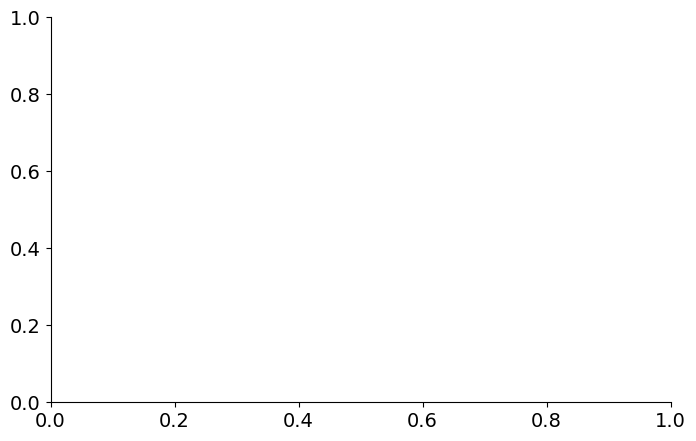

In [36]:
vis.plot_responsive_bars()

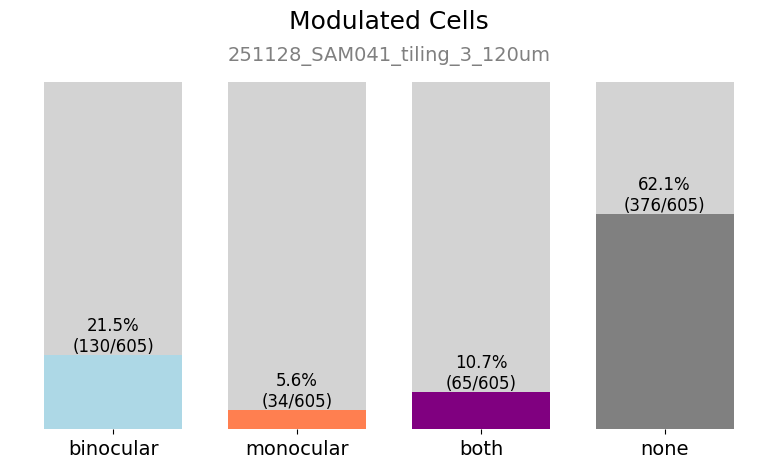

In [9]:
fig = visualizer.plot_modulation_bars()

binocular
monocular
both
none


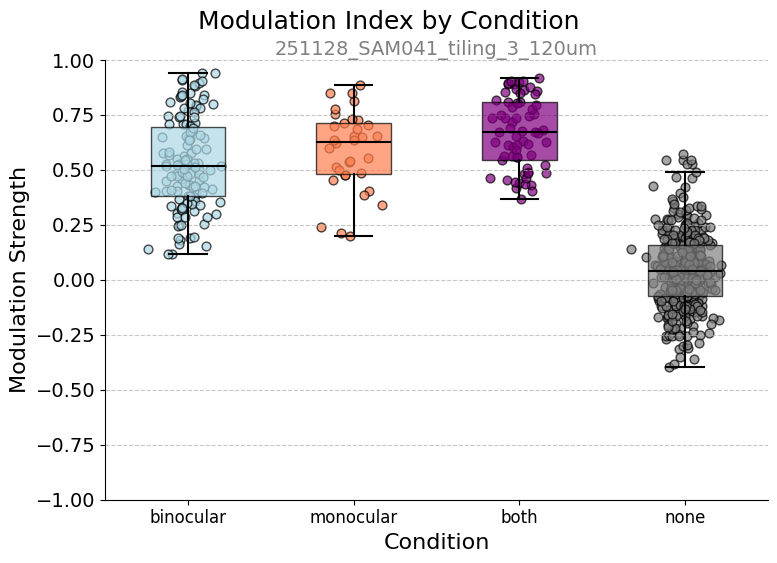

In [11]:
fig = visualizer.plot_modulation_index()

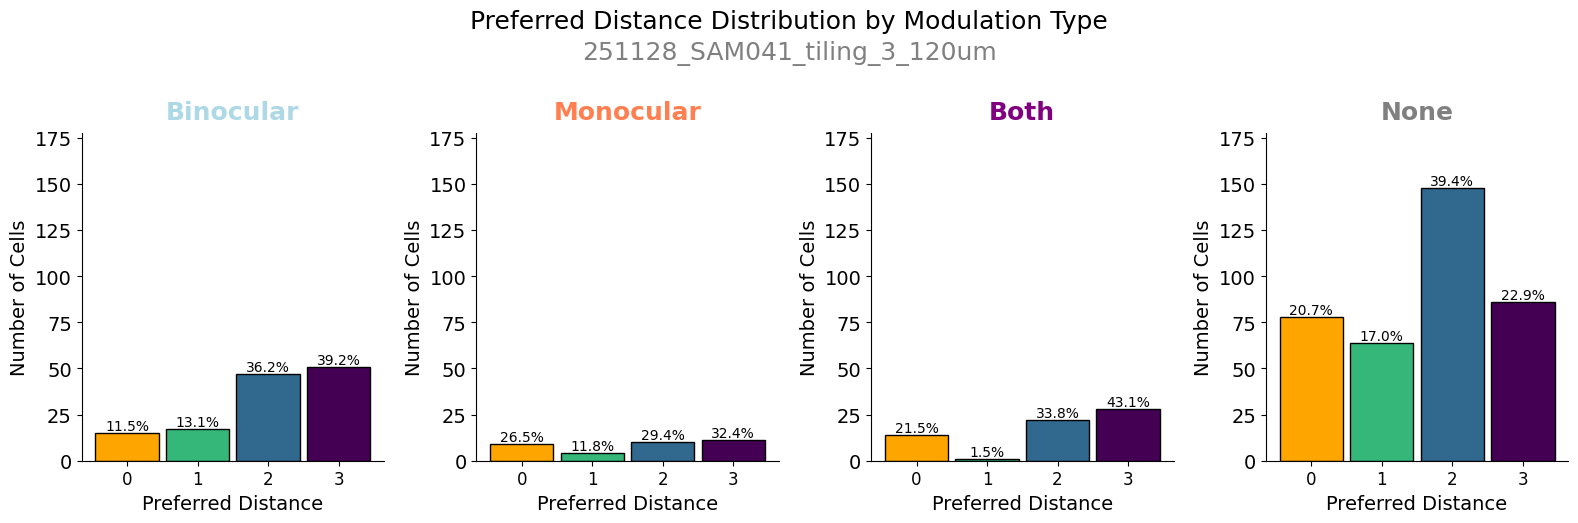

In [12]:
fig, axes = visualizer.plot_distance_bars()

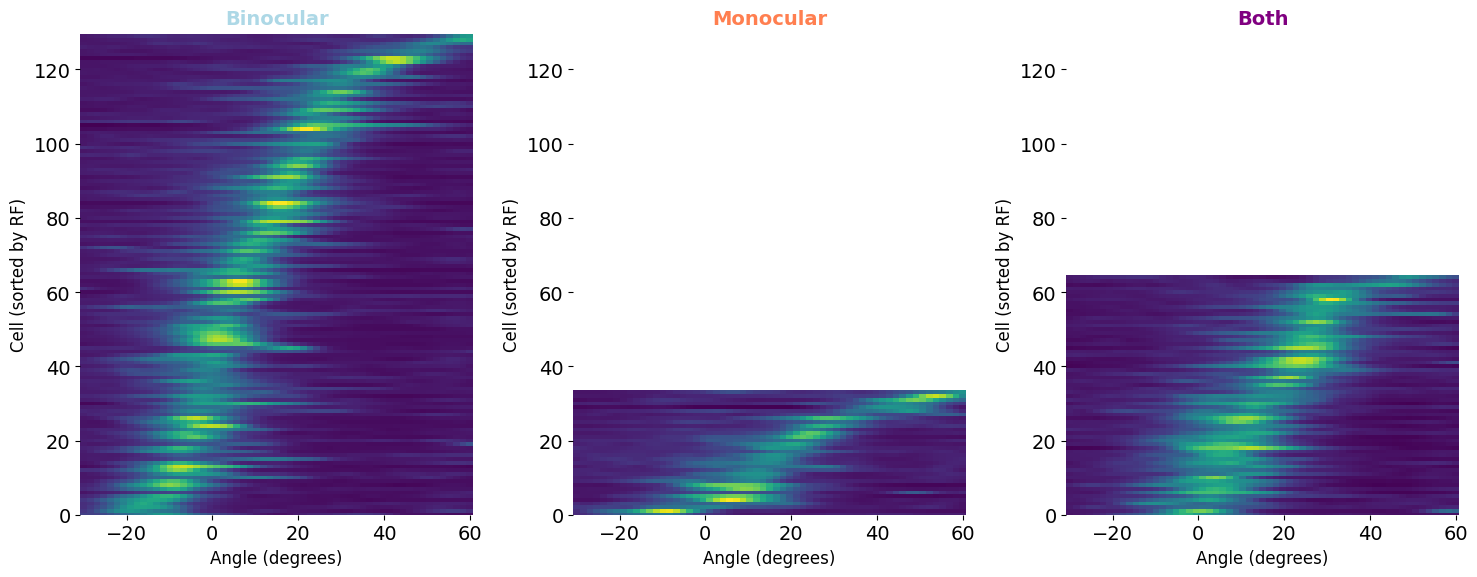

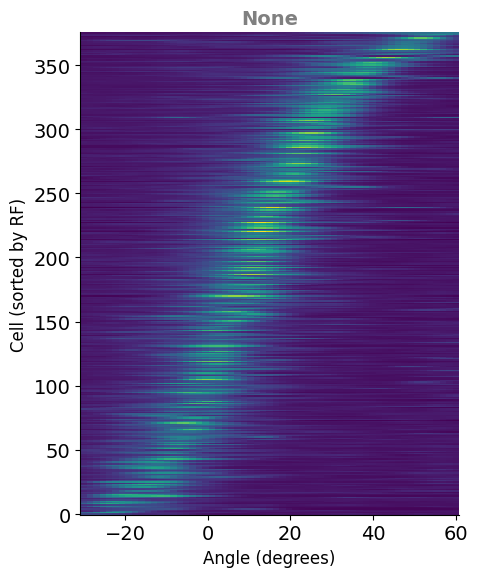

In [13]:
visualizer.plot_mean_traces()

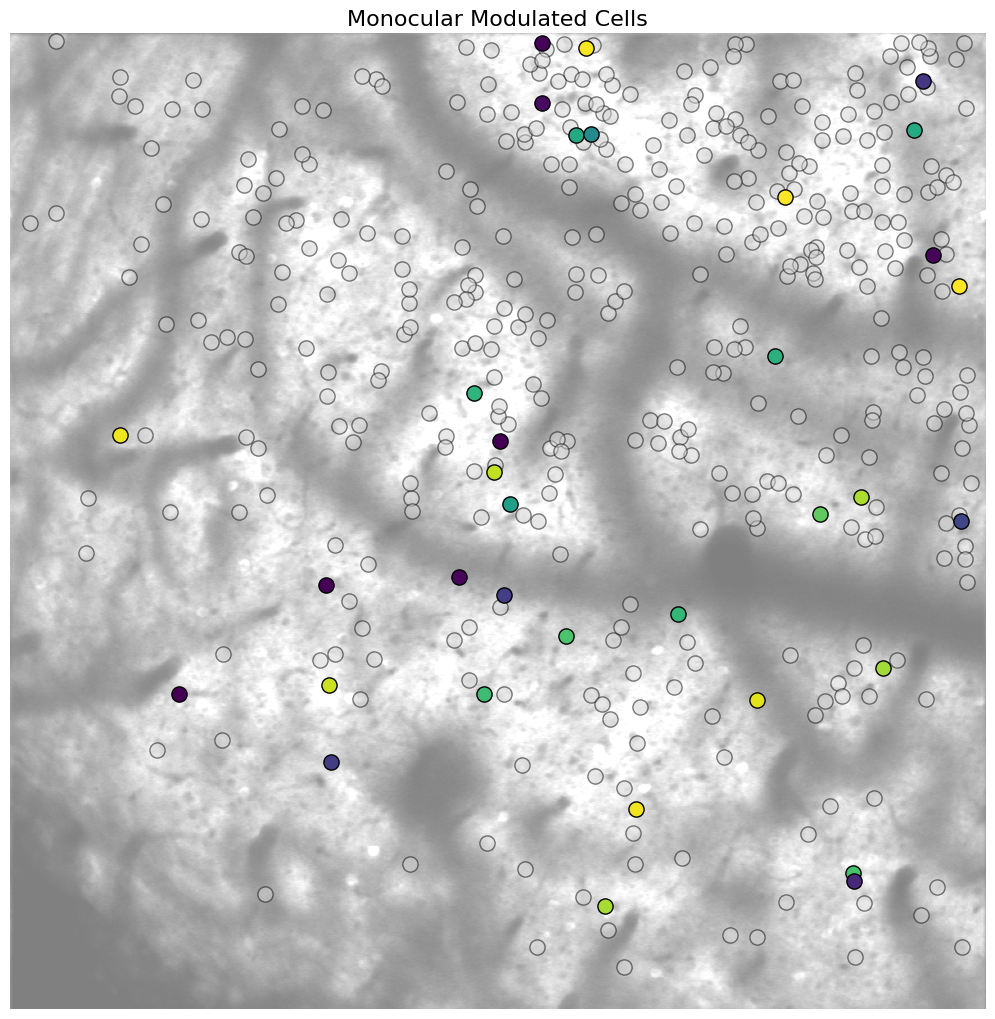

(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Monocular Modulated Cells'}>)

In [15]:
visualizer.plot_modulated_cells_map(condition='monocular')

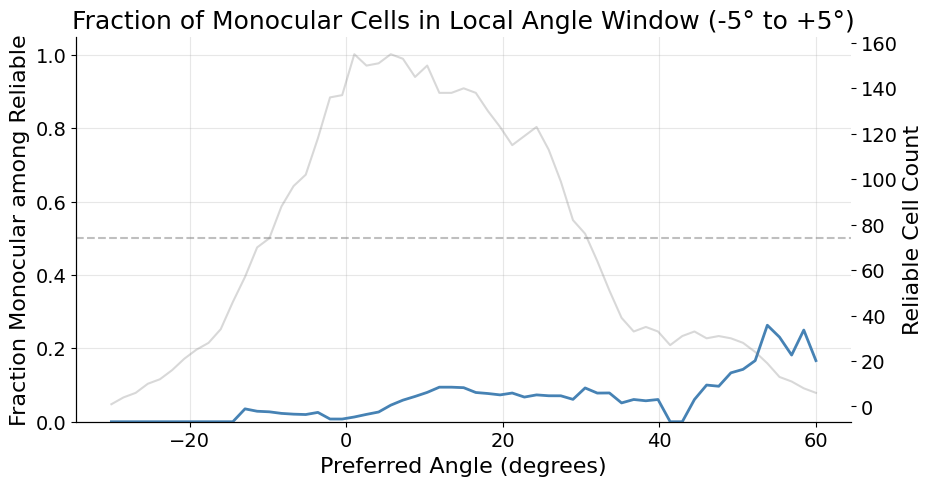

In [9]:
reliable_cells = SessionPlots.reliable_classes['reliable']
reliable_cells_rf = SessionPlots.extract_general_feature(cell=reliable_cells, feature='RF')

binocular_cells = SessionPlots.modulated_classes['monocular']
binocular_cells_rf = SessionPlots.extract_condition_feature(cell=binocular_cells, condition='monocular', feature='RF')

# Make a smooth plot: for each angle, show the fraction of binocular cells among reliable cells in a sliding RF window
import numpy as np
import matplotlib.pyplot as plt

# Use 1-degree step
angles = R.angle_range

# For each angle, compute mask of -5 to +5 degrees for reliable and binocular cells
frac_binocular_in_reliable = []
counts_reliable = []
counts_binocular = []

reliable_cells_rf = np.array(reliable_cells_rf)
binocular_cells_rf = np.array(binocular_cells_rf)

for ang in angles:
    rf_window = (reliable_cells_rf >= ang-5) & (reliable_cells_rf < ang+5)
    rel_count = np.sum(rf_window)
    # among reliable cells in the window, how many are also binocular? 
    # Take intersection of reliable cells in window and binocular cell RFs in window
    # But to avoid double-counting, match IDs, so do instead: count of binocular_cell RFs in window
    binoc_count = np.sum((binocular_cells_rf >= ang-5) & (binocular_cells_rf < ang+5))
    
    counts_reliable.append(rel_count)
    counts_binocular.append(binoc_count)
    if rel_count > 0:
        frac = binoc_count / rel_count
    else:
        frac = np.nan
    frac_binocular_in_reliable.append(frac)

plt.figure(figsize=(10,5))
plt.plot(angles, frac_binocular_in_reliable, color='steelblue', lw=2)
plt.xlabel('Preferred Angle (degrees)')
plt.ylabel('Fraction Monocular among Reliable')
plt.title('Fraction of Monocular Cells in Local Angle Window (-5° to +5°)')
plt.ylim(0, 1.05)
plt.axhline(0.5, color='gray', ls='--', alpha=0.5)
plt.grid(alpha=0.3)

# Optionally, overlay histogram in background to show reliable cell density
plt.twinx()
plt.plot(angles, counts_reliable, color='gray', alpha=0.3, label='Reliable cell count')
plt.ylabel('Reliable Cell Count')
plt.show()